<a href="https://colab.research.google.com/github/kkauandinizz/python_sis_26_2/blob/main/kauan_diniz_trabalho_bimestral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍫 Análise Exploratória: Avaliações de Chocolate

**Trabalho Bimestral** · Kauan Diniz

> **Como rodar no Google Colab:** envie este arquivo em *Arquivo → Fazer upload de notebook*, arraste o `kauan_diniz_chocolate.csv` para a pasta 📁 à esquerda (se esquecer, o notebook baixa a base sozinho) e clique em *Ambiente de execução → Executar tudo*.

**Pergunta do trabalho:** o que faz um chocolate receber uma nota melhor? Vou olhar a porcentagem de cacau e a quantidade de ingredientes.

In [14]:
"""
=====================================================================
Nome:                 Análise Exploratória - Avaliações de Chocolate
Versão:               1.0
Sintaxe:              Python 3 / Jupyter Notebook (.ipynb)
Descrição:            Análise exploratória de uma base com 2.530 barras
                      de chocolate avaliadas: contexto, estatísticas
                      descritivas e gráficos.
Linguagem:            Python 3
Sistema operacional:  Windows, Linux ou Google Colab
Requisitos:           pandas e matplotlib
Autor(es):            Kauan Diniz
Data de criação:      25/11/2026
Alterações:           25/11/2026 - v1.0 - versão inicial
=====================================================================
"""

# os: serve para checar se o arquivo da base está na pasta
import os

# pandas: biblioteca que lê a tabela e faz as contas
import pandas as pd

# matplotlib: biblioteca que desenha os gráficos
import matplotlib.pyplot as plt

## 1. Contexto

A base se chama **Flavors of Cacao** e traz avaliações de barras de chocolate feitas por um especialista (fonte: projeto TidyTuesday, no GitHub). **Cada linha é uma barra de chocolate**, com a nota dada (de 1 a 5), o fabricante, o país de origem do cacau, a porcentagem de cacau e os ingredientes.

A base tem mais de 500 linhas, como o trabalho pede.

In [15]:
# Nome do arquivo da base (no padrão pedido pelo professor)
arquivo = "kauan_diniz_chocolate.csv"

# Link original da base, usado se o arquivo não estiver na pasta
link = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv"

# Se o arquivo existe na pasta, leio ele; se não, leio direto do link
if os.path.exists(arquivo):
    df = pd.read_csv(arquivo)
else:
    df = pd.read_csv(link)

# Mostro as 5 primeiras linhas para conhecer a tabela
df.head()

,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [16]:
# .info() mostra as colunas, quantos valores não vazios cada uma tem e o tipo de dado
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2530 entries, 0 to 2529
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   ref                               2530 non-null   int64  
 1   company_manufacturer              2530 non-null   object 
 2   company_location                  2530 non-null   object 
 3   review_date                       2530 non-null   int64  
 4   country_of_bean_origin            2530 non-null   object 
 5   specific_bean_origin_or_bar_name  2530 non-null   object 
 6   cocoa_percent                     2530 non-null   object 
 7   ingredients                       2443 non-null   object 
 8   most_memorable_characteristics    2530 non-null   object 
 9   rating                            2530 non-null   float64
dtypes: float64(1), int64(2), object(7)
memory usage: 197.8+ KB


In [17]:
# shape mostra (quantidade de linhas, quantidade de colunas)
print("Linhas e colunas:", df.shape)

# Quantos valores vazios existem em cada coluna
df.isna().sum()

Linhas e colunas: (2530, 10)


,0
ref,0
company_manufacturer,0
company_location,0
review_date,0
country_of_bean_origin,0
specific_bean_origin_or_bar_name,0
cocoa_percent,0
ingredients,87
most_memorable_characteristics,0
rating,0


**O que vi:** a base tem 2.530 linhas e 10 colunas. Só a coluna `ingredients` tem valores vazios (87). Também notei que `cocoa_percent` está como texto (ex.: `"76%"`), então vou precisar converter para número antes de fazer contas.

In [18]:
# Tiro o símbolo "%" e transformo o texto em número (ex.: "76%" vira 76.0)
df["cocoa_percent"] = df["cocoa_percent"].str.replace("%", "").astype(float)

# Crio uma coluna com a quantidade de ingredientes, pegando o primeiro dígito de "3- B,S,C"
df["qtd_ingredientes"] = df["ingredients"].str[0].astype(float)

# Confiro o resultado
df[["cocoa_percent", "ingredients", "qtd_ingredientes", "rating"]].head()

,cocoa_percent,ingredients,qtd_ingredientes,rating
0,76.0,"3- B,S,C",3.0,3.25
1,76.0,"3- B,S,C",3.0,3.50
2,76.0,"3- B,S,C",3.0,3.75
3,68.0,"3- B,S,C",3.0,3.00
4,72.0,"3- B,S,C",3.0,3.00


## 2. Estatísticas descritivas

In [19]:
# describe() gera contagem, média, desvio, mínimo, quartis e máximo das colunas numéricas
df[["rating", "cocoa_percent", "qtd_ingredientes"]].describe().round(2)

,rating,cocoa_percent,qtd_ingredientes
count,2530.00,2530.00,2443.00
mean,3.20,71.64,3.04
std,0.45,5.62,0.91
min,1.00,42.00,1.00
25%,3.00,70.00,2.00
50%,3.25,70.00,3.00
75%,3.50,74.00,4.00
max,4.00,100.00,6.00


In [20]:
# Medidas da nota, uma por uma
print("Nota média:", round(df["rating"].mean(), 2))
print("Nota mediana:", df["rating"].median())
print("Nota mínima:", df["rating"].min())
print("Nota máxima:", df["rating"].max())

# Quantas barras tiraram a nota máxima (4.0)
print("Barras com nota 4.0:", (df["rating"] == 4.0).sum())

Nota média: 3.2
Nota mediana: 3.25
Nota mínima: 1.0
Nota máxima: 4.0
Barras com nota 4.0: 112


In [21]:
# Contagem de barras por nota (value_counts), organizada da menor para a maior nota
df["rating"].value_counts().sort_index()

,count
rating,
1.00,4
1.50,10
1.75,3
2.00,33
2.25,17
2.50,166
2.75,333
3.00,523
3.25,464


In [22]:
# Os 5 países que mais fornecem cacau para as barras avaliadas
df["country_of_bean_origin"].value_counts().head(5)

,count
country_of_bean_origin,
Venezuela,253
Peru,244
Dominican Republic,226
Ecuador,219
Madagascar,177


In [23]:
# Os 5 fabricantes com mais barras avaliadas
df["company_manufacturer"].value_counts().head(5)

,count
company_manufacturer,
Soma,56
Fresco,39
Arete,32
Bonnat,30
A. Morin,26


## 3. Visualizações

### Gráfico 1: Como as notas se distribuem?

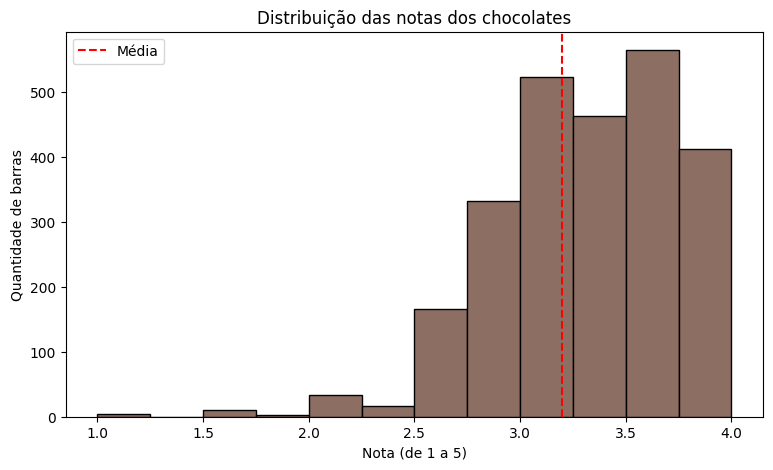

In [24]:
# Crio a figura com um tamanho bom para ler
plt.figure(figsize=(9, 5))

# Histograma: conta quantas barras têm cada nota (bins=12 faz 12 colunas)
plt.hist(df["rating"], bins=12, color="#8D6E63", edgecolor="black")

# Linha vertical vermelha na média, para comparar
plt.axvline(df["rating"].mean(), color="red", linestyle="--", label="Média")

# Título, nomes dos eixos e legenda
plt.title("Distribuição das notas dos chocolates")
plt.xlabel("Nota (de 1 a 5)")
plt.ylabel("Quantidade de barras")
plt.legend()

# Mostro o gráfico
plt.show()

**O que vi:** a maioria das barras ficou entre **3,0 e 3,5**, e quase nenhuma passou de 4,0. A nota média é **3,2**. Ou seja, nota alta é rara.

### Gráfico 2: Mais cacau significa nota maior?

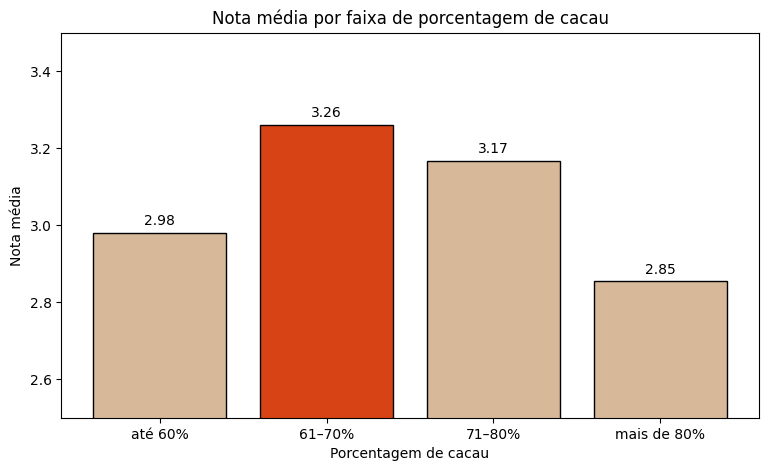

In [25]:
# Divido o % de cacau em 4 faixas: até 60, de 61 a 70, de 71 a 80 e acima de 80
df["faixa_cacau"] = pd.cut(df["cocoa_percent"], bins=[0, 60, 70, 80, 100],
                           labels=["até 60%", "61–70%", "71–80%", "mais de 80%"])

# Calculo a nota média de cada faixa
media_por_faixa = df.groupby("faixa_cacau", observed=True)["rating"].mean()

# Crio a figura
plt.figure(figsize=(9, 5))

# Gráfico de barras, com cores de chocolate
plt.bar(media_por_faixa.index.astype(str), media_por_faixa.values,
        color=["#D7B899", "#D84315", "#D7B899", "#D7B899"], edgecolor="black")

# Título e nomes dos eixos
plt.title("Nota média por faixa de porcentagem de cacau")
plt.xlabel("Porcentagem de cacau")
plt.ylabel("Nota média")

# O eixo Y começa em 2,5 para a diferença aparecer melhor
plt.ylim(2.5, 3.5)

# Escrevo o valor da média em cima de cada barra
for i, valor in enumerate(media_por_faixa.values):
    plt.text(i, valor + 0.02, round(valor, 2), ha="center")

plt.show()

**O que vi:** a melhor nota média (**3,26**) é das barras com **61–70%** de cacau. Acima de 80% a nota cai para **2,85**. Então mais cacau **não** significa chocolate melhor: o equilíbrio parece importar mais. *(Obs.: o eixo vertical começa em 2,5 para destacar as diferenças.)*

### Gráfico 3: Mais ingredientes significa nota maior?

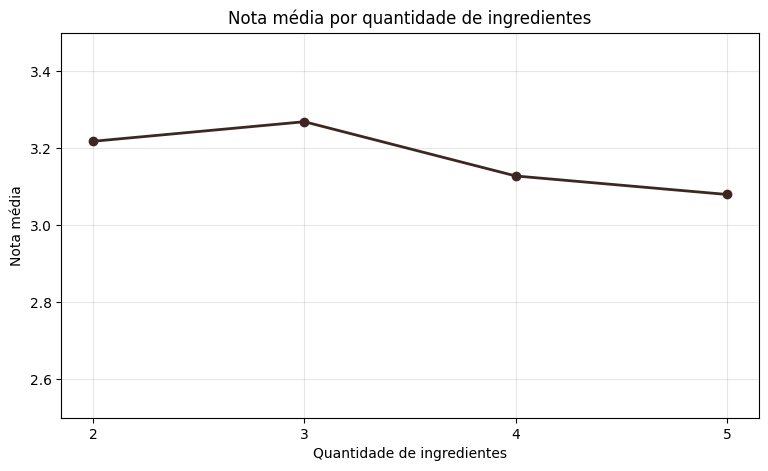

In [26]:
# Nota média por quantidade de ingredientes, só de 2 a 5 (6 e 1 têm pouquíssimas barras)
media_ingredientes = df[df["qtd_ingredientes"].between(2, 5)].groupby("qtd_ingredientes")["rating"].mean()

# Crio a figura
plt.figure(figsize=(9, 5))

# Gráfico de linha com bolinhas em cada ponto
plt.plot(media_ingredientes.index, media_ingredientes.values, marker="o", color="#3E2723", linewidth=2)

# Título e nomes dos eixos
plt.title("Nota média por quantidade de ingredientes")
plt.xlabel("Quantidade de ingredientes")
plt.ylabel("Nota média")

# Deixo só os números inteiros no eixo X e coloco uma grade leve
plt.xticks([2, 3, 4, 5])
plt.grid(alpha=0.3)

plt.ylim(2.5, 3.5)

plt.show()

**O que vi:** as receitas com **3 ingredientes** têm a melhor média (**3,27**) e a nota **cai** a cada ingrediente a mais (4 = 3,13; 5 = 3,08). Receita mais simples tende a ter nota melhor.

## 4. Conclusão

- A nota média dos chocolates é **3,2**, e nota 4,0 é rara.
- O "ponto ideal" de cacau fica entre **61% e 70%**; acima de 80% a nota cai.
- Receitas com **3 ingredientes** tiveram as melhores notas.

**Limitações:** as notas vêm de um único avaliador, então refletem o gosto dele; e os gráficos mostram relações, não provam causas.

**Fonte da base:** Flavors of Cacao, via TidyTuesday (https://github.com/rfordatascience/tidytuesday/tree/master/data/2022/2022-01-18).